# Synchronizing strata

*A small transformer trained on a hidden Markov model with designed synchronizing words: what its activations
represent, how that is learned, and which measurements of it can be trusted.*

This notebook reproduces and checks an earlier write-up of the same setup. It is a baseline: the hidden process
is a plug-in, so the interesting use is to change it and rerun (section 9). The code is the
[hmm-strata](https://github.com/kubasiemion/hmm-strata) package, cloned at tag `v0.1.0`.

**What is in it**

1. A 4-state, 6-token HMM with a rank-1 word `s` (every history collapses to one belief), a rank-2 word `f`
   (beliefs collapse onto a segment) and four full-rank "fold" tokens.
2. A 143,846-parameter transformer (4 layers, d=64, one 8-dim head per layer) trained on fresh samples.
3. Exact tools: the Bayes belief, the optimal next-token distribution, KL to it, all computed analytically.
4. Measurements: excess KL, a linear belief probe, spread of the point stratum, a history probe, learning order
   across checkpoints, error inheritance, and an ablation of the history directions.
5. What did **not** work (a local-dimension estimator), with the calibration that shows why.

**Headline results** (3 seeds of the setup of this notebook, 40k steps; it regenerates a fast single-seed version in minutes)

* The model reaches the Bayes-optimal predictor to within about 0.09 x 10^-3 nats per token, and its final
  residual stream linearly encodes the belief state (R² > 0.995).
* After the rank-1 word the activations are much tighter than after a fold token (variance ratio 0.03 to 0.06),
  but they are not a point: the residual stream keeps pre-sync history, decodable for a few steps.
* **Learning order depends on the scale it is measured on.** On linear scales the coarse next-token surface is
  learned before the belief probe saturates, but the probe's R² starts at 0.81, which makes it a poor clock. On a
  log scale, KL and belief-probe error improve together. The surplus history appears later (around step 10,000
  on all three seeds).
* Removing the linear directions that decode the surplus history hurts no more than removing matched control
  directions, but the removal is incomplete, so this does not show the history is unused.
* Error inheritance (does the model build belief t+1 from its belief at t?) is large at initialisation and mostly
  gone, but not entirely, by the end.

**Caveats** are in the last section: one HMM, one architecture, three seeds, and all thresholds are choices.

## 0. Setup

The package is cloned from GitHub at a fixed tag, so what you read in the repository is what runs here.
Set `MODE` below. `fast` trains one seed for 5,000 steps (a few minutes on a Colab GPU); `full` trains three
seeds for 40,000 steps (tens of minutes on a GPU, far too slow on CPU). A GPU runtime is recommended. The stored
outputs were produced in fast mode on an Intel Arc GPU (device `xpu`); on Colab the device is `cuda`.

In [1]:
![ -d hmm-strata ] || git clone -q --branch v0.1.0 --depth 1 https://github.com/kubasiemion/hmm-strata
import sys; sys.path.insert(0, "hmm-strata")

Note: switching to 'c52adc551d60df01081d0efedfb37c35f48e386a'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false



In [2]:
MODE = "fast"  #@param ["fast", "full"]

import json, time
from pathlib import Path
import numpy as np, torch
import matplotlib.pyplot as plt
from hmmstrata.device import pick
from hmmstrata.process import make
from hmmstrata import exact

DEV = pick()
STEPS, SEEDS = (5000, [0]) if MODE == "fast" else (40000, [0, 1, 2])
RESULTS = json.load(open("hmm-strata/notebooks/results.json"))   # shipped results (3 + 5 seeds, computed offline)
print("device:", DEV, "| mode:", MODE, "| steps:", STEPS, "| seeds:", SEEDS)

device: xpu | mode: fast | steps: 5000 | seeds: [0]


## 1. The process

Each token `x` is a matrix `T[x]`; `T[x][i, j] = P(emit x and move to state j | state i)`. Fold tokens are
emitted from the *destination* state (the convention of the original setup; the other choice gives a different
process and measurably different geometry). The image of a token's belief map has dimension `rank(T[x]) - 1`,
which gives the predictions we check: a point after `s`, a segment after `f`, a fractal after folds.

token ranks: {'0': 4, '1': 4, '2': 4, '3': 4, 's': 1, 'f': 2}
predicted stratum dimension (rank-1): {'0': 3, '1': 3, '2': 3, '3': 3, 's': 0, 'f': 1}
stationary distribution: [0.327 0.298 0.253 0.122]


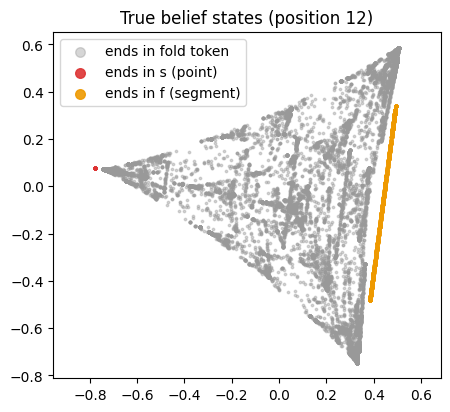

In [3]:
hmm = make("sync_strata", dest_emission=True)
print("token ranks:", {k: int(v) for k, v in zip(hmm.token_names, hmm.token_ranks())})
print("predicted stratum dimension (rank-1):", {k: int(v) for k, v in zip(hmm.token_names, hmm.stratum_dims())})
print("stationary distribution:", hmm.stationary().round(3))

# True Bayes beliefs at one position, projected on their two leading principal components.
toks, _ = exact.sample(hmm, 20000, 16, np.random.default_rng(0))
eta, probs, _ = exact.beliefs(hmm, toks)
t = 12
B = eta[:, t]
C = B - B.mean(0)
u, s, vt = np.linalg.svd(C, full_matrices=False)
P2 = C @ vt[:2].T
last = toks[:, t]
plt.figure(figsize=(5, 4.5))
for name, tok, col in [("ends in fold token", None, "#999"), ("ends in s (point)", 4, "#d33"), ("ends in f (segment)", 5, "#e90")]:
    m = (last < 4) if tok is None else (last == tok)
    plt.scatter(P2[m, 0], P2[m, 1], s=3, alpha=0.4 if tok is None else 0.9, c=col, label=name)
plt.legend(markerscale=4); plt.title("True belief states (position 12)"); plt.axis("equal"); plt.show()

## 2. Unit tests of the exact tools

Sampling frequencies match the analytic predictions, the Bayes predictor's cross-entropy equals its own
entropy, the belief after `s` is a single point, the error-inheritance Jacobian matches a finite difference
and separates a synthetic recursive estimator from a parallel one, and the ablation helper is the identity
when nothing is ablated.

In [4]:
import unittest
suite = unittest.defaultTestLoader.discover("hmm-strata/tests", pattern="test_*.py")
result = unittest.TextTestRunner(verbosity=1).run(suite)
assert result.wasSuccessful()

.

.

.

.

.

.

... (3 outputs left out)

.

.

.

----------------------------------------------------------------------
Ran 12 tests in 1.573s

OK


## 3. Train

Fresh sequences every step (no fixed dataset), context 16, batch 128, AdamW lr 1e-3, weight decay 0, cosine
decay to 0, no warmup. Checkpoints are log-spaced from step 0.

In [5]:
from hmmstrata.train import train
RUNS = {}
for seed in SEEDS:
    out = Path(f"runs/seed{seed}")
    t0 = time.time()
    n_params = train("sync_strata", {"dest_emission": True}, seed, STEPS, out, DEV, wd=0.0, n_ckpt=24)
    RUNS[seed] = out
    print(f"seed {seed}: {n_params:,} parameters, {time.time() - t0:.0f} s")

seed 0: 143,846 parameters, 80 s


## 4. Surface and geometry at the final checkpoint

* **Excess KL**: `KL(Bayes || model)` averaged over positions, in 10^-3 nats.
* **Probe R²**: a linear map from the final residual stream to the true belief, on held-out sequences.
* **Point ratio**: total variance of the residual vectors at contexts ending in `s`, divided by the same for
  contexts ending in fold token 0 at least 5 steps after a sync (the control that holds the last token fixed),
  each centred per position and averaged over positions 6 to 14.

Shipped results for 3 seeds (this configuration, 40k steps):

| seed | excess KL (1e-3) | probe R² | point ratio |
|---|---|---|---|
| 0 | 0.087 | 0.9965 | 0.057 |
| 1 | 0.085 | 0.9963 | 0.030 |
| 2 | 0.082 | 0.9958 | 0.059 |

Fast mode (5,000 steps) is not converged: expect an excess KL of roughly 0.4 x 10^-3 and a looser point ratio of
about 0.1 to 0.15. Use `full` to match the table.

The earlier write-up reported a point ratio of 0.056 and an excess KL of about 0.08 x 10^-3 after correcting a
bug of its own (an untrained position in its analysis). Emitting fold tokens from the source state instead of
the destination state gave a ratio of 0.09 to 0.20, so the emission convention matters.

In [6]:
from hmmstrata.analyze import analyze
live = {}
for seed, run in RUNS.items():
    a = analyze(run, dev=DEV)
    live[seed] = a
    print(f"seed {seed}: excess KL {1e3*a['excess_kl_nats']:.3f}e-3 | probe R2 {a['probe_r2_all']:.4f} | "
          f"point ratio (pos 6-14) {a['point_ratio_perpos_6_14']:.3f}")
    print("   KL (1e-3) by steps since the last sync:", {k: round(v, 3) for k, v in a["kl_e3_by_since_sync"].items()})

seed 0: excess KL 0.374e-3 | probe R2 0.9940 | point ratio (pos 6-14) 0.133
   KL (1e-3) by steps since the last sync: {0: 0.252, 1: 0.362, 2: 0.483, 4: 0.456, 8: 0.53}


### Surplus history

The belief after `s` is a single point, so the token *before* the `s` carries no information about the future:
any decoding of it above the majority baseline is history the model keeps but the Bayes predictor does not need.
The probe decodes that token from the residual stream `k` steps after the `s`, at the final layer and at each
layer for `k = 2`.

In [7]:
from hmmstrata.probes import evaluate
for seed, run in RUNS.items():
    r = evaluate(run, dev=DEV)
    print(f"seed {seed}: belief R2 by stream (embedding, layers 1-4):", " ".join(f"{v:.3f}" for v in r["belief_r2"]))
    print("  pre-sync token decoding, final layer (accuracy / majority baseline):")
    for k, (a, b, n) in r["presync_final"].items():
        print(f"    {k} steps after s: {a:.2f} / {b:.2f}")
    print("  k=2 by stream (embedding, L1..L4):", " ".join(f"{a:.2f}" for a, b in r["presync_layers"]))

seed 0: belief R2 by stream (embedding, layers 1-4): 0.751 0.948 0.982 0.990 0.993
  pre-sync token decoding, final layer (accuracy / majority baseline):
    1 steps after s: 0.89 / 0.24
    2 steps after s: 0.67 / 0.22
    3 steps after s: 0.52 / 0.24
    4 steps after s: 0.42 / 0.23
    6 steps after s: 0.31 / 0.23
    8 steps after s: 0.24 / 0.22
  k=2 by stream (embedding, L1..L4): 0.22 0.35 0.65 0.65 0.67


## 5. Learning order across training

For every checkpoint we measure KL, the belief-probe R² and the history decodable at `k = 2`. The answer to
"what is learned first" depends on the scale used to measure progress, so both readings are shown.

**Linear thresholds.** First checkpoint reaching fixed levels (the grid is log-spaced and coarse):

| run | KL < 5e-3 | R² > 0.99 | KL < 1e-3 | history k=2 at 90% of its gain |
|---|---|---|---|---|
| dest0 | 633 | 3996 | 10041 | 10041 |
| dest1 | 633 | 3996 | 10041 | 10041 |
| dest2 | 399 | 3996 | 15918 | 10041 |
| control0 | 1003 | 3996 | 15918 | 3996 |
| control1 | 633 | 3996 | 15918 | 25233 |
| control2 | 633 | 3996 | 15918 | 6334 |
| control3 | 1003 | 3996 | 15918 | 10041 |
| control4 | 1590 | 3996 | 15918 | 6334 |

On this reading the coarse surface (KL within 5e-3) comes before the belief probe saturates, and the last order
of magnitude of KL arrives after it, together with the surplus history.

**Log scale.** The step at which log(error) has covered 50% / 90% of its total drop, for KL and for the belief-probe
error `1 - R²`:

| run | KL (50% / 90%) | belief-probe error (50% / 90%) |
|---|---|---|
| dest0 | 633 / 40000 | 633 / 25233 |
| dest1 | 633 / 40000 | 633 / 15918 |
| dest2 | 399 / 40000 | 633 / 15918 |
| control0 | 399 / 40000 | 633 / 15918 |
| control1 | 633 / 40000 | 633 / 25233 |
| control2 | 633 / 40000 | 633 / 15918 |
| control3 | 1003 / 40000 | 1003 / 25233 |
| control4 | 399 / 40000 | 633 / 15918 |

The R² starts at 0.81, so it has little room to move and is a poor clock on a linear scale. On a log scale the two
track each other: half of the drop in both happens around step 400 to 1,000, and the probe error is done earlier
than KL (KL keeps improving to the end of training, as the learning rate decays). So "the surface is learned
before the geometry" holds only for linear thresholds, and should not be read as a general ordering. Measured
instead as "90% of the total KL improvement on a linear scale", KL looks finished by step 16 to 40, an artefact of
its large starting value.

`dest*` are the destination-emission runs of this notebook, `control*` an earlier variant (source-state emission,
weight decay 0.01). The three `dest` seeds agree on the history timing (step 10,041 on all three) and on a
decreasing history at k = 4; the earlier variant does not agree on the latter.

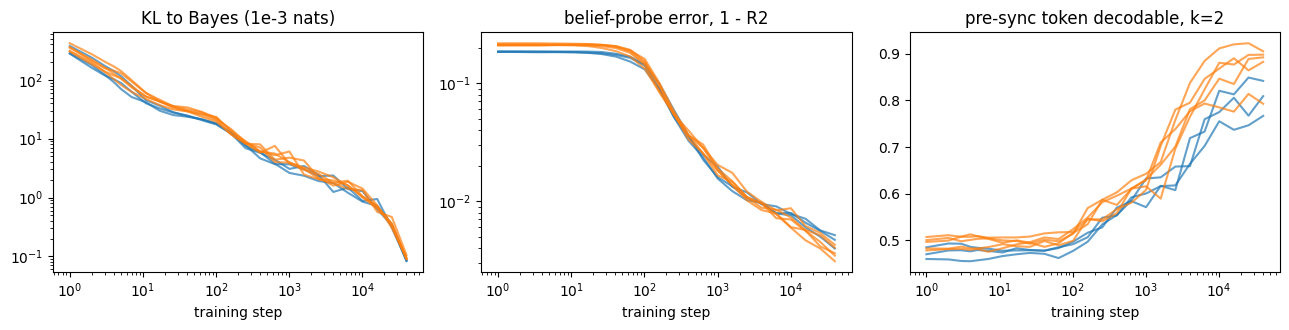

blue: destination-emission seeds (this notebook's setup), orange: earlier variant


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for name, o in RESULTS["series"].items():
    st = np.array([r["step"] for r in o]) + 1
    col = "C0" if name.startswith("dest") else "C1"
    ax[0].plot(st, [r["kl_e3"] for r in o], c=col, alpha=.7)
    ax[1].plot(st, [1 - r["belief_r2"] for r in o], c=col, alpha=.7)
    ax[2].plot(st, [r["hist_k2"] for r in o], c=col, alpha=.7)
ax[0].set_yscale("log"); ax[0].set_title("KL to Bayes (1e-3 nats)")
ax[1].set_yscale("log"); ax[1].set_title("belief-probe error, 1 - R2")
ax[2].set_title("pre-sync token decodable, k=2")
for a in ax: a.set_xscale("log"); a.set_xlabel("training step")
plt.tight_layout(); plt.show()
print("blue: destination-emission seeds (this notebook's setup), orange: earlier variant")

In [9]:
# Optional: the same series for the model(s) trained above (takes a few minutes).
RUN_SERIES = False
if RUN_SERIES:
    from hmmstrata.series import series
    for seed, run in RUNS.items():
        o = series(run, n=8000, dev=DEV)
        print(seed, [(r["step"], round(r["kl_e3"], 3), round(r["belief_r2"], 3), round(r["hist_k2"], 2)) for r in o][::4])

## 6. Error inheritance

If a model folds recursively, so that its belief at `t+1` is the true update applied to its belief at `t`, then
its error at `t` is carried to `t+1` through the Jacobian of the update. If it computes each position afresh
from the context, the errors are unrelated. For pairs of positions at depth `k` after an `s`, followed by a fold
token, the score is the correlation between the probe error at `t+1` and the probe error at `t` pushed through
the true Jacobian, minus the same correlation with the `t+1` errors shuffled among the pairs.

Shipped final-checkpoint values (real minus shuffled; depths 1 to 6):

| seed | k=1 | k=2 | k=3 | k=4 | k=5 | k=6 |
|---|---|---|---|---|---|---|
| 0 | -0.08 | +0.02 | +0.08 | +0.10 | +0.13 | +0.15 |
| 1 | -0.16 | +0.01 | +0.07 | +0.07 | +0.04 | +0.04 |
| 2 | -0.10 | -0.06 | -0.05 | -0.03 | -0.03 | -0.01 |

At initialisation the score is about +0.4 to +0.5 at depths 3 to 5. It decays slowly during training. The final
models compute each position mostly afresh, with a weak residual inheritance on some seeds. Depth 1 is negative
on most seeds and unexplained.

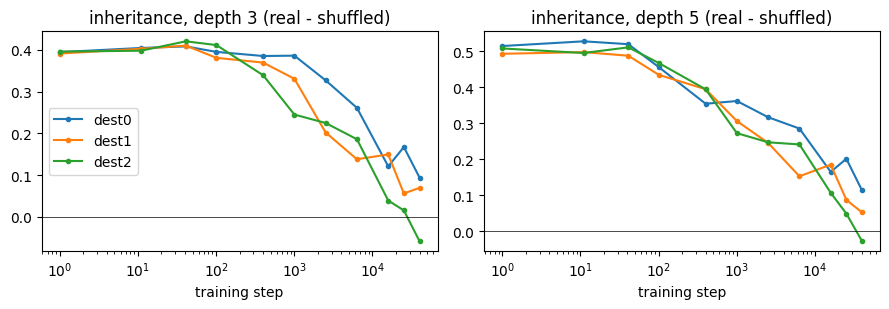

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for j, k in enumerate(("3", "5")):
    for s, d in RESULTS["inherit_dev"].items():
        st = sorted(int(x) for x in d)
        ax[j].plot(np.array(st) + 1, [d[str(x)][k][0] - d[str(x)][k][1] for x in st], marker="o", ms=3, label=s)
    ax[j].set_xscale("log"); ax[j].axhline(0, c="k", lw=.5); ax[j].set_title(f"inheritance, depth {k} (real - shuffled)")
    ax[j].set_xlabel("training step")
ax[0].legend(); plt.tight_layout(); plt.show()

In [11]:
from hmmstrata.inherit import inheritance
for seed, run in RUNS.items():
    r = inheritance(run, dev=DEV, n=30000)
    print(f"seed {seed}: real - shuffled by depth:", {k: round(v[0] - v[1], 3) for k, v in r.items()})

seed 0: real - shuffled by depth: {1: -0.075, 2: 0.138, 3: 0.215, 4: 0.187, 5: 0.182, 6: 0.209}


## 7. Is the surplus history load-bearing?

The last order of magnitude of KL arrives together with the surplus history, which suggests the history may not
be surplus to the *model*: a finite network cannot hold the exact belief, so it might refine it with raw recent
history. A direct test: take the 15 linear directions that decode the pre-sync token (at 1, 2 and 3 steps after
`s`), make them orthogonal to the belief subspace, and mean-ablate them at one residual stream. If the history
carries the fine surface, KL should rise sharply.

Two controls are needed. The history directions turn out to have low variance (1 to 6% of the total), so a naive
random subspace is not a fair control: it removes high-variance directions and raises KL by a factor of 50 or
more, which says nothing about history. The control used is a decoder with the same regression form fitted to
*shuffled* labels (same low-variance profile, no history information). The belief-probe subspace is ablated as a
reference.

Overall KL after ablation (10^-3 nats), shipped results, destination-emission seeds, final checkpoints:

| seed | stream | dim | baseline | history removed | shuffled control | belief removed | k=2 decodable (refit) |
|---|---|---|---|---|---|---|---|
| 0 | 2 | 15 | 0.087 | 0.112 | 0.117 | 0.095 | 0.82 to 0.68 |
| 0 | 3 | 15 | 0.087 | 0.116 | 0.127 | 0.111 | 0.82 to 0.66 |
| 0 | 4 | 15 | 0.087 | 0.215 | 0.136 | 0.144 | 0.81 to 0.65 |
| 1 | 2 | 15 | 0.085 | 0.120 | 0.118 | 0.089 | 0.73 to 0.56 |
| 1 | 3 | 15 | 0.085 | 0.105 | 0.107 | 0.111 | 0.73 to 0.51 |
| 1 | 4 | 15 | 0.085 | 0.112 | 0.126 | 0.102 | 0.75 to 0.55 |
| 2 | 2 | 15 | 0.083 | 0.209 | 0.117 | 0.097 | 0.80 to 0.73 |
| 2 | 3 | 15 | 0.083 | 0.099 | 0.117 | 0.092 | 0.84 to 0.67 |
| 2 | 4 | 15 | 0.083 | 0.129 | 0.156 | 0.105 | 0.85 to 0.62 |

(stream = which residual the ablation is applied to: 2 and 3 are after those blocks, 4 is the final residual.)

* KL rises by a factor of 1.2 to 2.5, never anywhere near the 5 x 10^-3 level, and the shuffled control raises it
  by about as much. The history ablation clearly exceeds its control in only two of nine cases.
* So removing the main linear history directions does not specifically hurt. **This is weak evidence**, because
  the removal is incomplete: a refit decoder still reads the pre-sync token at 0.5 to 0.7 afterwards, so the
  history is also stored in directions the linear decoders did not find. A stronger test would remove them
  iteratively until the decodability is at chance.

In [12]:
# Live version on the model(s) trained above (stream 3 only, a minute or so). Fast-mode models are not converged.
from hmmstrata.ablate import run as run_ablation
for seed, run in RUNS.items():
    for stream, r in run_ablation(run, streams=(3,), n=15000, n_random=2, dev=DEV).items():
        print(f"seed {seed}, stream {stream}, {r['dim']} history directions; k=2 decodable {r['dec_before']:.2f} -> {r['dec_after']:.2f}")
        print("  overall KL (1e-3):", {k: round(r[k]['all'], 3) for k in ('base', 'hist', 'random_mean', 'belief')},
              "(base / history removed / shuffled control / belief removed)")

seed 0, stream 3, 15 history directions; k=2 decodable 0.65 -> 0.57
  overall KL (1e-3): {'base': 0.374, 'hist': 0.628, 'random_mean': 0.586, 'belief': 0.742} (base / history removed / shuffled control / belief removed)


## 8. What did not work: local dimension of the residual stream

The natural way to look for "strata" in activations is a local-dimension estimator. We tried TwoNN and a
correlation-dimension slope on the residual stream. They did **not** discriminate the strata. The calibration
below uses synthetic sets of known dimension (0 to 3) with noise in 5 extra dimensions. TwoNN reads 7 to 9
whatever the true dimension, and the slopes drop to zero beyond the extent of the set, so a point and a short
segment look alike. Conclusions drawn from those estimators on the real activations would not be safe, and the
true belief geometry (computed from the HMM) is the reliable reference.

In [13]:
from hmmstrata.calibrate import synthetic
synthetic()

SYNTHETIC (noise: sigma=1 in 5 dims). cols: TwoNN MLE | slopes at 2,4,8,16,32 x NN


true d=0 L=  1   6.83  5.07 | 4.77±0.02 4.09±0.01 1.98±0.02 0.04±0.00 0.00±0.00


true d=1 L= 20   8.10  5.97 | 5.27±0.02 3.56±0.02 1.28±0.01 0.62±0.01 0.00±0.00


true d=1 L=100   8.01  5.88 | 4.80±0.03 2.58±0.02 1.16±0.01 0.96±0.00 0.82±0.00


true d=2 L= 20   9.23  6.69 | 5.44±0.02 3.09±0.02 1.69±0.01 0.46±0.01 0.00±0.00


true d=2 L=100   8.62  5.70 | 3.90±0.03 2.31±0.01 1.94±0.00 1.70±0.01 1.19±0.01


true d=3 L=100   7.37  4.41 | 3.51±0.02 2.96±0.01 2.64±0.01 2.03±0.01 0.25±0.02


## 9. Make the hidden state your own

A process is a token-labelled HMM: `T[x, i, j]` with `sum_x T[x]` row-stochastic, plus optional annotations
(named state groups, token and state events, an `expected` dictionary for predictions written down before
training). Register it by name and everything above runs unchanged. The example below makes the fold part
asymmetric (a different stay probability per state, keeping `s` and `f`). It is only constructed and checked
here; training and analysing it is the exercise.

In [14]:
import numpy as np
from hmmstrata.process import register, make
from hmmstrata.process.base import HMM

@register("sync_strata_asym")
def sync_strata_asym(stays=(0.95, 0.85, 0.7, 0.5), match=0.70, p_s=0.08, p_f=0.12):
    S, F = 4, 4
    V = F + 2
    p_fold = 1 - p_s - p_f
    M = np.zeros((S, S))
    for i, st in enumerate(stays):
        M[i] = (1 - st) / (S - 1); M[i, i] = st
    E = np.full((S, F), (1 - match) / (F - 1)); np.fill_diagonal(E, match)
    T = np.zeros((V, S, S))
    for x in range(F):
        T[x] = p_fold * M * E[:, x][None, :]            # destination emission
    T[F] = p_s * np.outer(np.ones(S), np.eye(S)[0])      # s: any state -> state 0 (rank 1)
    T[F + 1] = p_f * np.array([[0, .8, .2, 0]] * 2 + [[0, .2, .8, 0]] * 2)   # f: collapse to a segment (rank 2)
    h = HMM(name="sync_strata_asym", T=T, pi0=np.full(S, 1 / S), state_names=[f"q{i}" for i in range(S)],
            token_names=[str(i) for i in range(F)] + ["s", "f"], token_events={"s": {F}, "f": {F + 1}})
    h.pi0 = h.stationary()
    return h

h2 = make("sync_strata_asym")
print("ranks:", {k: int(v) for k, v in zip(h2.token_names, h2.token_ranks())})
print("stationary distribution:", h2.stationary().round(3), "(every state should keep non-trivial mass)")
# To train and analyse it:  train("sync_strata_asym", {}, seed, STEPS, Path("runs/asym"), DEV, wd=0.0)
# (hmmstrata.analyze looks up the token names 's' and 'f', so it works for any process that keeps them.)

ranks: {'0': 4, '1': 4, '2': 4, '3': 4, 's': 1, 'f': 2}
stationary distribution: [0.467 0.333 0.148 0.052] (every state should keep non-trivial mass)


## 10. Limits

* One HMM, one architecture and context length, three seeds in the shipped results. Seeds disagree noticeably
  on the point ratio (0.03 to 0.06) and on how much history is retained.
* Probe-based measurements are only as good as the linear probe; the error-inheritance score goes through one.
* Every threshold in the learning-order tables is a choice, and the checkpoint grid is coarse. The ordering of
  KL against probe error changes with the scale (linear against log).
* The history ablation removes only linear directions and the removal is incomplete.
* The point-stratum variance ratio measures spread, not dimension.
* The earlier variant (source-state emission) and this one differ, so numbers from the two must not be mixed.

## References

* Shai, Marzen, Teixeira, Gietelink Oldenziel, Riechers (2024). *Transformers represent belief state geometry in
  their residual stream.* https://arxiv.org/abs/2405.15943
* Piotrowski, Riechers, Filan, Shai (2025). *Constrained belief updates explain geometric structures in
  transformer representations.* https://arxiv.org/abs/2502.01954
* Robinson, Dey, Chiang (2025). *Token embeddings violate the manifold hypothesis.* https://arxiv.org/abs/2504.01002
* Robinson, Dey, Chiang (2024). *The structure of the token space for large language models.* https://arxiv.org/abs/2410.08993
* Wang et al. (2025). *Beyond the 80/20 Rule: High-Entropy Minority Tokens Drive Effective Reinforcement
  Learning for LLM Reasoning.* https://arxiv.org/abs/2506.01939

The setup follows an earlier private write-up produced with a Claude model; the destination-emission HMM, the
point-ratio definition and the surplus-history idea come from it. The checks here (the position-15 artefact in the
original analysis, emission convention, learning order, inheritance, the history ablation, the failed dimension
estimators) are ours.